# 05 · Redes neuronales pequeñas entrenadas desde cero

**Objetivo:** entrenar redes neuronales pequeñas para texto y compararlas con el mejor modelo lineal actual, la **regresión logística elasticnet ajustada por CV anidada sobre V2 (F1 macro 0.794 ± 0.022, `04`)**. Como segunda referencia usamos V3 + SVM lineal (0.782 ± 0.016, `03`).

**Qué esperamos, y qué no.** Con 1731 tuits (≈1.4k por fold de entrenamiento) **no esperamos ganarle a TF-IDF + modelo lineal**: las redes necesitan muchos más datos para aprender representaciones mejores que el conteo de palabras. Lo que queremos medir es:
1. cuánto se acercan;
2. qué decisiones de diseño importan (cabeza compartida, ponderación de positivos, embeddings propios, variante de preprocesamiento);
3. si se equivocan en tuits **distintos** a los del modelo lineal (diversidad), que es lo que puede aprovechar el ensamble del `07`;
4. cuánto **sobreajustan**: F1 en train frente a validación.

No forzamos el resultado.

**Conceptos** (en orden de aparición):
- **Embedding:** cada palabra (o carácter, o n-grama) se representa con un vector denso de 32–100 números, que la red aprende durante el entrenamiento.
- **BCE (*binary cross-entropy*):** la pérdida estándar para salidas sí/no. Con 3 etiquetas, la red tiene 3 salidas sigmoide y se suma la BCE de cada una.
- **Dropout:** durante el entrenamiento se "apaga" al azar una fracción de neuronas (30–50%) en cada paso. Así la red no depende de unas pocas y sobreajusta menos.
- **Early stopping:** se entrena época a época y se para cuando la pérdida en una **validación interna** deja de mejorar; se conserva la mejor época.
- **CNN (red convolucional 1D):** recorre el texto con filtros de 2–7 palabras o caracteres que detectan patrones locales (*cállate + insulto*). Después se queda con la activación máxima de cada filtro en todo el texto (*max-pooling*).
- **GRU / BiGRU:** red recurrente que lee el texto palabra a palabra manteniendo una memoria. La versión bidireccional lo lee en ambos sentidos.
- **Pooling por atención:** en lugar de tomar la media o el máximo, la red aprende un peso para cada palabra y combina sus representaciones con esos pesos. Los pesos se pueden inspeccionar para ver qué palabras pesaron más.
- **Seed-ensembling:** entrenar la misma red con 3 semillas aleatorias distintas y promediar sus probabilidades. Reduce el ruido del entrenamiento, que en redes pequeñas es grande.

**Por qué redes pequeñas y muy regularizadas.** Con ≈1.2k ejemplos para entrenar (descontada la validación interna), una red con cientos de miles de parámetros **memoriza** el train en pocas épocas. Usamos:
- embeddings de 32–100 dimensiones y capas de 64–128 unidades;
- dropout de 0.3–0.5 y AdamW con *weight decay* (penaliza pesos grandes);
- *gradient clipping* (limita el tamaño de cada actualización);
- lotes de 64, un máximo de 30 épocas y early stopping con paciencia 5.

**Reglas que se respetan:**
- Nada preentrenado: vocabularios, TF-IDF, embeddings (también Word2Vec y FastText de gensim) y pesos se ajustan en `fit()`, **dentro de cada fold**, solo con el texto de entrenamiento del fold (ni test ni corpus externos).
- El fold de validación externo **nunca** decide cuándo parar: el early stopping usa una validación interna (12% del train del fold, estratificada por combinación de etiquetas).
- El modelo final (todo el train) se entrena con un número **fijo** de épocas: la mediana de las mejores épocas de los folds.
- Mismo posprocesamiento que el `03`/`04` (umbral elegido en los otros folds, jerarquía HS=0 ⇒ TR=0 y tuits vacíos → 000): es el mismo componente compartido (`modeling.decide`).

## 1. Configuración, hardware y referencias

In [1]:
import json
import platform
import time
import warnings

import gensim
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
import torch
from IPython.display import display
from sklearn.exceptions import ConvergenceWarning

import modeling as md
import neural as nn_
import preprocessing as pp
from common import FIGURES_DIR, LABELS, PROCESSED_DIR, SEED, evaluate_oof, load_test, load_train, make_folds

warnings.filterwarnings("ignore", category=ConvergenceWarning)
warnings.filterwarnings("ignore", category=UserWarning, module="torch")
nn_.set_seed(SEED)
sklearn.set_config(display="text")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "axes.titleweight": "bold", "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 240)
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.max_rows", 200)
ARCH_COLORS = {"nn_mlp": "#2a78d6", "nn_fasttext": "#1baf7a", "nn_cnn_word": "#eb6834", "nn_cnn_char": "#4a3aa7",
               "nn_bigru": "#e34948"}
N_JOBS = 5          # los 5 folds en procesos paralelos
FOLD_THREADS = 2    # hilos de torch por proceso (5 × 2 = 10 núcleos)
FINAL_THREADS = 8   # hilos para los modelos finales (un solo proceso)


def savefig(fig, name):
    fig.savefig(FIGURES_DIR / f"05_{name}.png", dpi=120, bbox_inches="tight")


print(f"Python {platform.python_version()} | torch {torch.__version__} | scikit-learn {sklearn.__version__} | "
      f"gensim {gensim.__version__} | SEED = {SEED}")
print(f"GPU CUDA: {torch.cuda.is_available()} | Apple MPS: {torch.backends.mps.is_available()} | "
      f"núcleos: {torch.get_num_threads()} hilos por defecto -> se entrena en CPU")
train = load_train()
test = load_test()
Y = train[LABELS].to_numpy()
folds = make_folds(train)
folds2 = make_folds(train, seed=SEED + 1, path=PROCESSED_DIR / "folds_seed2.csv")  # solo para confirmar
pp.load_lemma_cache(PROCESSED_DIR / "lemma_cache.parquet")
texts = train["text"]
print(f"Train: {len(train)} | Test: {len(test)} | folds: {folds.value_counts().sort_index().to_dict()} | "
      f"folds_seed2 coincide con folds en {100 * (folds == folds2).mean():.0f}% de las filas")

Python 3.14.6 | torch 2.14.1 | scikit-learn 1.9.1 | gensim 4.4.0 | SEED = 42
GPU CUDA: False | Apple MPS: True | núcleos: 4 hilos por defecto -> se entrena en CPU
Train: 1731 | Test: 1154 | folds: {0: 347, 1: 346, 2: 346, 3: 346, 4: 346} | folds_seed2 coincide con folds en 22% de las filas


**Hardware.** Hay GPU de Apple (MPS) pero entrenamos en **CPU**. Con redes de este tamaño la CPU basta, y en CPU el entrenamiento es **determinista** con semillas fijas (`torch.use_deterministic_algorithms`). Cada fold se entrena en su propio proceso con 2 hilos.

**Referencias.** No se reentrenan: sus predicciones OOF se leen de `models/oof_predictions.parquet` y se evalúan con el mismo protocolo. La comparación es pareada por fold: **empate** si |media de Δ| < desviación de Δ entre folds.

In [2]:
RESULTS = {}
T_START = time.perf_counter()
oof_store = pd.read_parquet(md.OOF_PATH)


def stored_cv(model_id):
    oof = oof_store[oof_store["model_id"] == model_id].set_index("id").loc[train["id"], [f"p_{l}" for l in LABELS]].to_numpy()
    at_05, tuned = md._summarize_folds(oof, Y, folds)
    return {"oof": oof, "at_05": at_05, "tuned": tuned}


REFS = {m: stored_cv(m) for m in ["V2__logreg__nested", "V3__linsvm", "V3__linsvm__nested", "V3__et__word__k2000"]}
REF = "V2__logreg__nested"
for k, r in REFS.items():
    print(f"{k}: F1 macro ajustado {r['tuned']['F1_macro'].mean():.4f} ± {r['tuned']['F1_macro'].std():.4f}")


def _clock(s):
    m, s = divmod(int(s), 60)
    return f"{m:d}:{s:02d}"


def run_nn(variant, arch, tag=None, stage="cribado", step=None, keep_models=False, cv_folds=None, **params):
    """CV de una red (3 semillas por fold) + modelo final con épocas fijas. Cachea por model_id."""
    model_id = md.model_name(variant, arch, "tfidf", tag) + ("__folds2" if cv_folds is not None else "")
    if model_id in RESULTS:
        return RESULTS[model_id]
    start = time.perf_counter()
    print(f"[{step or '·'}] {model_id} ...", end=" ", flush=True)
    model = nn_.NeuralTweetClassifier(variant, arch, n_threads=FOLD_THREADS, **params)
    cv = nn_.neural_cross_validate(model, texts, Y, folds if cv_folds is None else cv_folds, n_jobs=N_JOBS,
                                   keep_models=keep_models)
    res = {"model_id": model_id, "kind": "nn", "variant": variant, "classifier": arch, "params": params,
           "stage": stage, "cv": cv}
    if cv_folds is None:  # modelo final solo con los folds principales
        epochs = nn_.final_epochs(cv)
        final = nn_.NeuralTweetClassifier(variant, arch, n_threads=FINAL_THREADS, fixed_epochs=epochs,
                                          thresholds=md.best_thresholds(Y, cv["oof"]), **params).fit(texts, Y)
        res.update(model=final, size_mb=nn_.neural_size_mb(final), test_proba=final.predict_proba(test["text"]),
                   test_pred=final.predict(test["text"]))
    RESULTS[model_id] = res
    f1 = cv["tuned"]["F1_macro"]
    seeds = [t["F1_macro"].mean() for t in cv["tuned_per_seed"]]
    print(f"F1 macro {f1.mean():.4f} ± {f1.std():.4f} (semillas por separado: {np.mean(seeds):.4f} ± {np.std(seeds, ddof=1):.4f}) "
          f"| {time.perf_counter() - start:.0f} s | total {_clock(time.perf_counter() - T_START)}", flush=True)
    return res


def run_sk(variant, classifier, features, tag=None, stage="cribado", step=None, cv_folds=None, grid=None, params=None):
    """Modelos de scikit-learn (regresión logística sobre embeddings promediados y referencias lineales)."""
    model_id = md.model_name(variant, classifier, features, tag) + ("__folds2" if cv_folds is not None else "")
    if model_id in RESULTS:
        return RESULTS[model_id]
    start = time.perf_counter()
    print(f"[{step or '·'}] {model_id} ...", end=" ", flush=True)
    f = folds if cv_folds is None else cv_folds
    if grid is None:
        cv = md.cross_validate(md.TweetToxicClassifier(variant, classifier, features=features, clf_params=params),
                               texts, Y, f, n_jobs=N_JOBS, return_train=True)
        final_params = params
    else:
        cv = md.nested_cross_validate(variant, classifier, features, grid, texts, Y, f, n_jobs=N_JOBS)
        final_params = None
    res = {"model_id": model_id, "kind": "sk", "variant": variant, "classifier": classifier, "params": {},
           "stage": stage, "cv": cv}
    if cv_folds is None:
        final = md.TweetToxicClassifier(variant, classifier, thresholds=md.best_thresholds(Y, cv["oof"]),
                                        features=features, clf_params=final_params).fit(texts, Y)
        res.update(model=final, size_mb=md.model_size_mb(final), test_proba=final.predict_proba(test["text"]),
                   test_pred=final.predict(test["text"]))
    RESULTS[model_id] = res
    f1 = cv["tuned"]["F1_macro"]
    print(f"F1 macro {f1.mean():.4f} ± {f1.std():.4f} | {time.perf_counter() - start:.0f} s | "
          f"total {_clock(time.perf_counter() - T_START)}", flush=True)
    return res


def cv_of(model_id):
    return RESULTS[model_id]["cv"] if model_id in RESULTS else REFS[model_id]


def verdict(d):
    if d.abs().max() == 0:
        return "igual"
    if abs(d.mean()) < d.std():
        return "empate"
    return "mejor" if d.mean() > 0 else "peor"


def paired(a, b):
    d = cv_of(a)["tuned"]["F1_macro"] - cv_of(b)["tuned"]["F1_macro"]
    return {"Δ (media)": round(d.mean(), 4), "Δ desv.": round(d.std(), 4), "folds mejor": int((d > 0).sum()),
            "veredicto": verdict(d)}


def summarize(ids, ref=REF):
    rows = []
    for i in ids:
        r = RESULTS[i]
        t = r["cv"]["tuned"]
        row = {"model_id": i, "variante": r["variant"], **{lab: round(t[f"F1_{lab}"].mean(), 3) for lab in LABELS},
               "macro": round(t["F1_macro"].mean(), 4), "desv.": round(t["F1_macro"].std(), 4),
               "micro": round(t["F1_micro"].mean(), 4), "micro desv.": round(t["F1_micro"].std(), 4)}
        if "train" in r["cv"]:
            row["macro train"] = round(r["cv"]["train"]["F1_macro"].mean(), 4)
            row["brecha train − val"] = round(row["macro train"] - row["macro"], 4)
        if r["kind"] == "nn":
            seeds = [s["F1_macro"].mean() for s in r["cv"]["tuned_per_seed"]]
            row.update({"1 semilla (media)": round(np.mean(seeds), 4), "desv. entre semillas": round(np.std(seeds, ddof=1), 4)})
        row.update({f"Δ vs {ref}": paired(i, ref)["Δ (media)"], "Δ desv.": paired(i, ref)["Δ desv."],
                    "veredicto": paired(i, ref)["veredicto"], "CV (s)": round(r["cv"]["fit_seconds"])})
        if "size_mb" in r:
            row["tamaño (MB)"] = round(r["size_mb"], 2)
        rows.append(row)
    return pd.DataFrame(rows).set_index("model_id").sort_values("macro", ascending=False)

V2__logreg__nested: F1 macro ajustado 0.7937 ± 0.0216
V3__linsvm: F1 macro ajustado 0.7817 ± 0.0160
V3__linsvm__nested: F1 macro ajustado 0.7888 ± 0.0215
V3__et__word__k2000: F1 macro ajustado 0.7670 ± 0.0216


## 2. Cribado de arquitecturas (V1 y V3)

Cada arquitectura con su configuración por defecto: cabeza compartida, BCE sin ponderar, embeddings aleatorios y 3 semillas por fold.

| Arquitectura | Entrada | Tamaño |
|---|---|---|
| `nn_mlp` | TF-IDF palabras (1–2) + caracteres (2–5) del 03 | 1 capa oculta de 128, dropout 0.5 |
| `nn_fasttext` | ids de palabras + n-gramas de caracteres 3–5 con *hashing* a 20 000 cubetas | embedding 100 promediado, dropout 0.3, lr 5e-3 |
| `nn_cnn_word` | palabras (vocabulario del fold, frecuencia ≥ 2, `<unk>` para el resto) | embedding 100, 64 filtros de 2, 3 y 4 palabras |
| `nn_cnn_char` | caracteres ASCII (hasta 300) | embedding 32, 64 filtros de 3, 5 y 7 caracteres |
| `nn_bigru` | palabras | embedding 100, GRU bidireccional de 64 + atención |

Además, como **arquitectura 5a**, probamos Word2Vec y FastText propios (gensim, entrenados en el fold) **promediados** como entrada de una regresión logística.

In [3]:
ARCHS = ["nn_mlp", "nn_fasttext", "nn_cnn_word", "nn_cnn_char", "nn_bigru"]
jobs = [(v, a) for v in ["V1", "V3"] for a in ARCHS]
for k, (v, a) in enumerate(jobs, 1):
    run_nn(v, a, stage="cribado", step=f"{k}/{len(jobs)}", keep_models=(a == "nn_bigru" and v == "V3"))
for k, (v, e) in enumerate([(v, e) for v in ["V1", "V3"] for e in ["emb-w2v", "emb-ft"]], 1):
    run_sk(v, "logreg", e, stage="cribado", step=f"5a {k}/4")
screen_ids = [i for i, r in RESULTS.items() if r["stage"] == "cribado"]
screen = summarize(screen_ids)
display(screen)

[1/10] V1__nn_mlp ... F1 macro 0.7520 ± 0.0094 (semillas por separado: 0.7503 ± 0.0033) | 35 s | total 0:38
[2/10] V1__nn_fasttext ... F1 macro 0.7319 ± 0.0174 (semillas por separado: 0.7332 ± 0.0080) | 15 s | total 0:53
[3/10] V1__nn_cnn_word ... F1 macro 0.7601 ± 0.0168 (semillas por separado: 0.7433 ± 0.0072) | 127 s | total 2:59
[4/10] V1__nn_cnn_char ... F1 macro 0.7607 ± 0.0156 (semillas por separado: 0.7535 ± 0.0090) | 721 s | total 15:00
[5/10] V1__nn_bigru ... F1 macro 0.7330 ± 0.0158 (semillas por separado: 0.7225 ± 0.0141) | 67 s | total 16:07
[6/10] V3__nn_mlp ... F1 macro 0.7503 ± 0.0094 (semillas por separado: 0.7439 ± 0.0038) | 32 s | total 16:39
[7/10] V3__nn_fasttext ... F1 macro 0.7280 ± 0.0169 (semillas por separado: 0.7293 ± 0.0014) | 17 s | total 16:56
[8/10] V3__nn_cnn_word ... F1 macro 0.7448 ± 0.0151 (semillas por separado: 0.7436 ± 0.0065) | 150 s | total 19:26
[9/10] V3__nn_cnn_char ... F1 macro 0.7564 ± 0.0148 (semillas por separado: 0.7449 ± 0.0020) | 655 s 

Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


F1 macro 0.6867 ± 0.0207 | 4 s | total 31:31
[5a 2/4] V1__logreg__emb-ft ... 

Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


F1 macro 0.6839 ± 0.0164 | 5 s | total 31:36
[5a 3/4] V3__logreg__emb-w2v ... 

Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


F1 macro 0.7050 ± 0.0284 | 4 s | total 31:40
[5a 4/4] V3__logreg__emb-ft ... 

Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


F1 macro 0.6972 ± 0.0097 | 5 s | total 31:46


,variante,HS,TR,AG,macro,desv.,micro,micro desv.,macro train,brecha train − val,1 semilla (media),desv. entre semillas,Δ vs V2__logreg__nested,Δ desv.,veredicto,CV (s),tamaño (MB)
model_id,,,,,,,,,,,,,,,,,
V1__nn_cnn_char,V1,0.760,0.787,0.736,0.7607,0.0156,0.7582,0.0166,0.9227,0.1620,0.7535,0.0090,-0.0329,0.0206,peor,483,0.42
V1__nn_cnn_word,V1,0.746,0.813,0.721,0.7601,0.0168,0.7550,0.0146,0.9518,0.1917,0.7433,0.0072,-0.0336,0.0167,peor,94,3.13
V3__nn_cnn_char,V3,0.752,0.776,0.741,0.7564,0.0148,0.7547,0.0146,0.9130,0.1566,0.7449,0.0020,-0.0372,0.0199,peor,461,0.43
V1__nn_mlp,V1,0.743,0.787,0.727,0.7520,0.0094,0.7485,0.0096,0.9614,0.2094,0.7503,0.0033,-0.0417,0.0165,peor,28,68.44
V3__nn_mlp,V3,0.748,0.777,0.725,0.7503,0.0094,0.7480,0.0111,0.9583,0.2080,0.7439,0.0038,-0.0433,0.0152,peor,26,67.26
V3__nn_cnn_word,V3,0.731,0.801,0.703,0.7448,0.0151,0.7397,0.0130,0.9430,0.1982,0.7436,0.0065,-0.0489,0.0179,peor,113,3.09
V1__nn_bigru,V1,0.722,0.788,0.690,0.7330,0.0158,0.7291,0.0127,0.8246,0.0916,0.7225,0.0141,-0.0606,0.0213,peor,48,3.31
V3__nn_bigru,V3,0.721,0.785,0.691,0.7322,0.0194,0.7272,0.0221,0.8258,0.0936,0.7168,0.0029,-0.0615,0.0335,peor,46,3.27
V1__nn_fasttext,V1,0.742,0.756,0.698,0.7319,0.0174,0.7300,0.0186,0.8941,0.1622,0.7332,0.0080,-0.0618,0.0224,peor,13,26.43


**Interpretación del cribado:**
- **Ninguna red alcanza al mejor lineal** (0.794). Todas son "peores" según el criterio pareado, con diferencias entre −0.033 y −0.066. Por arquitectura (V1 / V3):
  - **CNN de caracteres:** 0.761 / 0.756;
  - **CNN de palabras:** 0.760 / 0.745;
  - **MLP sobre TF-IDF:** 0.752 / 0.750;
  - **BiGRU:** 0.733 / 0.732;
  - **estilo fastText:** 0.732 / 0.728.
- **Word2Vec y FastText propios promediados con regresión logística** son lo peor: 0.684–0.705.
- **V1 rinde igual o mejor que V3 en todas las redes.** La diferencia más grande es la de la CNN de palabras (0.760 frente a 0.745).
- **Promediar 3 semillas ayuda casi siempre:** la media de las semillas por separado queda hasta 0.017 por debajo del promedio (por ejemplo, la CNN de palabras en V1 pasa de 0.743 a 0.760). La excepción es fastText, donde no gana nada.
- **Coste:**
  - la CNN de caracteres es la más lenta: 11–12 min por arquitectura, incluyendo la CV y el modelo final;
  - el resto tarda ≤ 2.5 min;
  - el MLP ocupa 67 MB (una capa de 36 mil × 128 por semilla) y la CNN de caracteres solo 0.4 MB.
- El aviso `Exception ignored in: ... our_dot_float` lo imprime gensim (compilado desde su rama de desarrollo para Python 3.14). No hay ninguna excepción real detrás, y el entrenamiento es determinista.

### Curvas de aprendizaje (fold 0, semilla 0)

Pérdida BCE en el entrenamiento y en la validación interna, época a época. Si la del entrenamiento sigue bajando mientras la de validación sube, la red está **sobreajustando** (memorizando el train). El punto marca la época que eligió el early stopping.

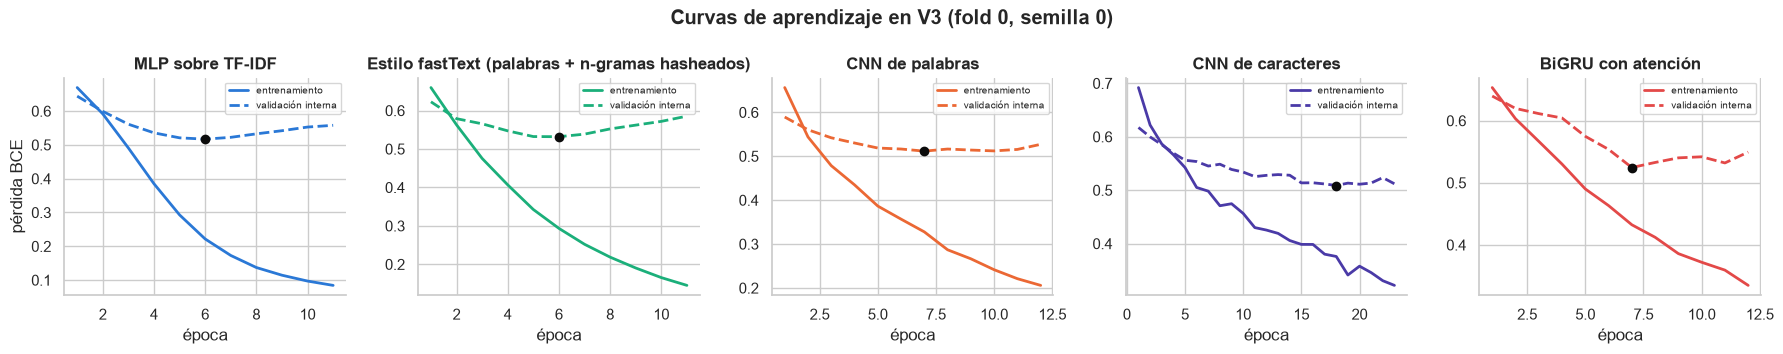

Mejor época (V3) por fold y semilla: {'nn_mlp': [[6, 6, 5], [8, 7, 8], [7, 7, 7], [7, 7, 6], [7, 7, 7]], 'nn_fasttext': [[6, 5, 5], [7, 7, 7], [6, 6, 7], [6, 6, 6], [6, 5, 5]], 'nn_cnn_word': [[7, 7, 6], [8, 9, 10], [12, 13, 11], [18, 12, 12], [12, 12, 7]], 'nn_cnn_char': [[18, 22, 16], [18, 20, 20], [26, 25, 23], [29, 29, 21], [19, 22, 21]], 'nn_bigru': [[7, 8, 6], [10, 12, 11], [9, 7, 11], [10, 9, 12], [11, 9, 12]]}


In [4]:
fig, axes = plt.subplots(1, len(ARCHS), figsize=(18, 3.6), sharey=False)
for ax, a in zip(axes, ARCHS):
    curve = RESULTS[md.model_name("V3", a, "tfidf")]["cv"]["curves"][0][0]
    ep = np.arange(1, len(curve["train"]) + 1)
    ax.plot(ep, curve["train"], color=ARCH_COLORS[a], lw=2, label="entrenamiento")
    ax.plot(ep, curve["val"], color=ARCH_COLORS[a], lw=2, ls="--", label="validación interna")
    best = int(np.argmin(curve["val"])) + 1
    ax.plot(best, curve["val"][best - 1], "o", color="#0b0b0b", ms=6)
    ax.set(title=md.CLASSIFIER_NAMES[a], xlabel="época", ylabel="pérdida BCE" if a == ARCHS[0] else "")
    ax.legend(fontsize=7)
fig.suptitle("Curvas de aprendizaje en V3 (fold 0, semilla 0)", fontweight="bold")
fig.tight_layout()
savefig(fig, "learning_curves")
plt.show()
print("Mejor época (V3) por fold y semilla:",
      {a: [[e[0] for e in fold] for fold in RESULTS[md.model_name("V3", a, "tfidf")]["cv"]["best_epochs"]] for a in ARCHS})

**Interpretación:** en las cinco arquitecturas la pérdida de entrenamiento baja sin parar, mientras que la de validación interna toca fondo pronto y después **sube o se aplana**: es el patrón típico del sobreajuste. El early stopping corta en ese mínimo.
- **MLP y fastText:** 5–8 épocas;
- **BiGRU:** 6–12 épocas;
- **CNN de palabras:** 6–18 épocas;
- **CNN de caracteres:** 16–29, la que más tarda en sobreajustar. En algunos folds llega cerca del máximo de 30 épocas, así que quizá admitía alguna más.

### Métricas de entrenamiento frente a validación: ¿cuánto sobreajustan?

Para cada modelo del cribado calculamos el F1 en tres conjuntos de cada fold, siempre con el mismo umbral y la misma jerarquía:
- **train:** los ejemplos con los que se ajustaron los pesos. En las redes es el 88% del fold de entrenamiento; en los lineales, el fold completo. Es un F1 *dentro de la muestra*.
- **validación interna** (solo redes): el 12% que eligió la época del early stopping. Es algo optimista, porque se usó para decidir cuándo parar.
- **validación externa (OOF):** el fold que el modelo nunca vio. Es la cifra que se reporta en todo el notebook.

La **brecha train − validación** mide el sobreajuste. Un modelo de texto con miles de rasgos casi siempre tiene un F1 de train cercano a 1: lo informativo es compararlo con la brecha de los modelos lineales de referencia y ver si la validación sigue siendo buena. Como referencia lineal recalculamos con train:
- `V3 + SVM lineal`;
- la regresión logística elasticnet con los hiperparámetros finales del `04` (C=10, l1_ratio=0.5) en V2, sin CV anidada, para poder medir su train.

[ref 1/2] V3__linsvm ... F1 macro 0.7817 ± 0.0160 | 3 s | total 31:49
[ref 2/2] V2__logreg__en-C10 ... F1 macro 0.7937 ± 0.0216 | 24 s | total 32:13


,variante,train,validación interna,validación externa (OOF),brecha train − OOF,train HS,train TR,train AG
model_id,,,,,,,,
V1__nn_cnn_char,V1,0.9227,0.7454,0.7607,0.1620,0.917,0.934,0.917
V1__nn_cnn_word,V1,0.9518,0.7502,0.7601,0.1917,0.954,0.958,0.944
V1__nn_mlp,V1,0.9614,0.7333,0.7520,0.2094,0.976,0.955,0.954
V1__nn_bigru,V1,0.8246,0.7418,0.7330,0.0916,0.797,0.875,0.802
V1__nn_fasttext,V1,0.8941,0.7240,0.7319,0.1622,0.909,0.900,0.874
V1__logreg__emb-w2v,V1,0.7494,NaN,0.6867,0.0627,0.738,0.794,0.716
V1__logreg__emb-ft,V1,0.7343,NaN,0.6839,0.0504,0.732,0.766,0.705
V2__logreg__en-C10,V2,0.9934,NaN,0.7937,0.1997,0.997,0.995,0.988
V3__linsvm,V3,0.9942,NaN,0.7817,0.2125,0.996,0.995,0.992


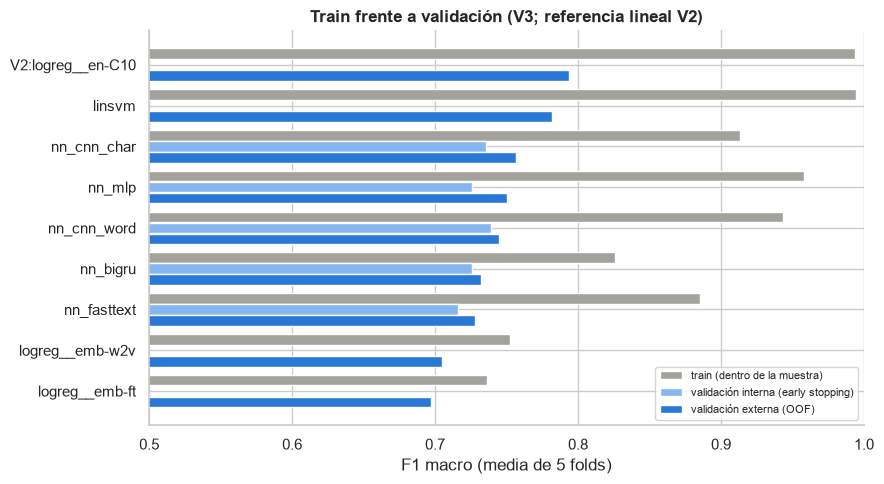

In [5]:
lin_refs = [run_sk("V3", "linsvm", "tfidf", stage="referencia", step="ref 1/2"),
            run_sk("V2", "logreg", "tfidf", tag="en-C10", stage="referencia", step="ref 2/2", params={"C": 10.0, "l1_ratio": 0.5})]
rows = []
for i in screen_ids + [r["model_id"] for r in lin_refs]:
    cv = RESULTS[i]["cv"]
    row = {"model_id": i, "variante": RESULTS[i]["variant"],
           "train": round(cv["train"]["F1_macro"].mean(), 4),
           "validación interna": round(cv["inner_val"]["F1_macro"].mean(), 4) if "inner_val" in cv else np.nan,
           "validación externa (OOF)": round(cv["tuned"]["F1_macro"].mean(), 4)}
    row["brecha train − OOF"] = round(row["train"] - row["validación externa (OOF)"], 4)
    row.update({f"train {lab}": round(cv["train"][f"F1_{lab}"].mean(), 3) for lab in LABELS})
    rows.append(row)
overfit = pd.DataFrame(rows).set_index("model_id").sort_values(["variante", "validación externa (OOF)"], ascending=[True, False])
display(overfit)

v3 = overfit[overfit["variante"].isin(["V3", "V2"])].sort_values("validación externa (OOF)")
fig, ax = plt.subplots(figsize=(9, 5))
y = np.arange(len(v3))
ax.barh(y + 0.27, v3["train"], height=0.26, color="#a3a29c", label="train (dentro de la muestra)")
ax.barh(y, v3["validación interna"], height=0.26, color="#86b6ef", label="validación interna (early stopping)")
ax.barh(y - 0.27, v3["validación externa (OOF)"], height=0.26, color="#2a78d6", label="validación externa (OOF)")
ax.set(yticks=y, yticklabels=[m.replace("V3__", "").replace("V2__", "V2:") for m in v3.index], xlim=(0.5, 1.0),
       xlabel="F1 macro (media de 5 folds)", title="Train frente a validación (V3; referencia lineal V2)")
ax.legend(fontsize=8, loc="lower right")
fig.tight_layout()
savefig(fig, "train_vs_validation")
plt.show()

**Interpretación (sobreajuste):**
- **Los lineales también "memorizan":** F1 de train 0.993–0.994 frente a 0.782–0.794 en validación, una brecha de ≈0.20–0.21. Con decenas de miles de rasgos casi cualquier modelo separa bien el train. Lo que importa es cuánto conserva en validación.
- **El MLP se comporta como un lineal:** train 0.96, brecha 0.21, pero con menos validación (0.750).
- **Las CNN sobreajustan algo menos:** brecha 0.16 en la de caracteres y 0.19–0.20 en la de palabras.
- **La BiGRU tiene la menor brecha (0.09)**, pero porque ni siquiera ajusta bien el train (0.82): le falta aprender más que le sobra memorizar.
- **Los embeddings promediados con regresión logística** apenas llegan a 0.73–0.75 en train: la representación es demasiado pobre (subajuste).
- **La validación interna** (0.716–0.750) queda muy cerca de la externa (0.728–0.761), en general algo por debajo: el early stopping no está dando una cifra optimista.

## 3. Decisiones de diseño, una cada vez (V3)

Cada decisión se compara con la configuración por defecto de la misma arquitectura (diferencia pareada por fold):
1. **Cabeza compartida frente a 3 redes independientes**, en las dos mejores arquitecturas del cribado. Una red con 3 salidas aprende una representación común para las tres etiquetas, lo que encaja con la jerarquía HS ⊃ TR; tres redes no comparten nada.
2. **`pos_weight` en la BCE**, que da más peso a los positivos de cada etiqueta (proporción negativos/positivos), frente a la BCE sin ponderar. Como el umbral se ajusta después, puede que no importe.
3. **Inicialización de los embeddings (P8):** aleatoria frente a Word2Vec o FastText propios (gensim, skip-gram, 100 dimensiones, entrenados con el texto del fold). Se prueba en la CNN de palabras y en la BiGRU, que no ven caracteres.

In [6]:
v3_rank = screen[(screen["variante"] == "V3") & screen.index.str.contains("__nn_")].index
TOP2 = [RESULTS[i]["classifier"] for i in v3_rank[:2]]
print("Dos mejores arquitecturas en V3:", TOP2)
design = []
jobs = [(a, "indep", {"head": "independent"}) for a in TOP2] + [(a, "posw", {"pos_weight": True}) for a in TOP2] \
     + [(a, init, {"init": init}) for a in ["nn_cnn_word", "nn_bigru"] for init in ["w2v", "ft"]]
for k, (a, tag, params) in enumerate(jobs, 1):
    r = run_nn("V3", a, tag=tag, stage="diseño", step=f"{k}/{len(jobs)}", **params)
    base = md.model_name("V3", a, "tfidf")
    design.append({"decisión": {"indep": "3 redes independientes", "posw": "pos_weight en la BCE",
                                "w2v": "init Word2Vec propio", "ft": "init FastText propio"}[tag],
                   "arquitectura": a, "F1 macro": round(r["cv"]["tuned"]["F1_macro"].mean(), 4),
                   "por defecto": round(RESULTS[base]["cv"]["tuned"]["F1_macro"].mean(), 4), **paired(r["model_id"], base)})
design = pd.DataFrame(design).set_index(["decisión", "arquitectura"])
display(design)

Dos mejores arquitecturas en V3: ['nn_cnn_char', 'nn_mlp']
[1/8] V3__nn_cnn_char__indep ... F1 macro 0.7569 ± 0.0124 (semillas por separado: 0.7506 ± 0.0035) | 1867 s | total 63:21
[2/8] V3__nn_mlp__indep ... F1 macro 0.7439 ± 0.0168 (semillas por separado: 0.7484 ± 0.0008) | 88 s | total 64:49
[3/8] V3__nn_cnn_char__posw ... F1 macro 0.7449 ± 0.0145 (semillas por separado: 0.7458 ± 0.0026) | 616 s | total 75:05
[4/8] V3__nn_mlp__posw ... F1 macro 0.7437 ± 0.0094 (semillas por separado: 0.7458 ± 0.0020) | 31 s | total 75:36
[5/8] V3__nn_cnn_word__w2v ... 

Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


F1 macro 0.7581 ± 0.0072 (semillas por separado: 0.7579 ± 0.0025) | 167 s | total 78:23
[6/8] V3__nn_cnn_word__ft ... 

Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


F1 macro 0.7559 ± 0.0096 (semillas por separado: 0.7566 ± 0.0019) | 191 s | total 81:34
[7/8] V3__nn_bigru__w2v ... 

Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


F1 macro 0.7330 ± 0.0106 (semillas por separado: 0.7236 ± 0.0049) | 65 s | total 82:39
[8/8] V3__nn_bigru__ft ... 

Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


F1 macro 0.7320 ± 0.0177 (semillas por separado: 0.7301 ± 0.0033) | 67 s | total 83:46


F1 macro  por defecto  Δ (media)  Δ desv.  folds mejor veredicto
decisión               arquitectura                                                                  
3 redes independientes nn_cnn_char     0.7569       0.7564     0.0005   0.0065            3    empate
                       nn_mlp          0.7439       0.7503    -0.0064   0.0150            2    empate
pos_weight en la BCE   nn_cnn_char     0.7449       0.7564    -0.0115   0.0086            0      peor
                       nn_mlp          0.7437       0.7503    -0.0066   0.0044            0      peor
init Word2Vec propio   nn_cnn_word     0.7581       0.7448     0.0133   0.0155            4    empate
init FastText propio   nn_cnn_word     0.7559       0.7448     0.0111   0.0122            4    empate
init Word2Vec propio   nn_bigru        0.7330       0.7322     0.0008   0.0233            2    empate
init FastText propio   nn_bigru        0.7320       0.7322    -0.0002   0.0226            3    empate

**Interpretación** (las dos mejores arquitecturas en V3 fueron la CNN de caracteres y el MLP):
- **Cabeza compartida frente a 3 redes independientes: empate** (CNN de caracteres +0.0005 ± 0.0065; MLP −0.006 ± 0.015). Compartir no cuesta nada y es 3 veces más barato. La CNN de caracteres con 3 redes tardó 31 min, por encima del tope de tiempo previsto. **Se mantiene la cabeza compartida.**
- **`pos_weight` en la BCE empeora de forma consistente:** CNN de caracteres −0.012 ± 0.009 y MLP −0.007 ± 0.004, peor en los 5 folds en ambos casos. Como el umbral ya se ajusta después, ponderar los positivos solo añade ruido. **No se usa.**
- **Inicialización con embeddings propios (P8):**
  - en la CNN de palabras sube +0.013 con Word2Vec y +0.011 con FastText (4 de 5 folds), aunque dentro de la desviación (empate);
  - además reduce la variación entre semillas (rango 0.005 frente a 0.013) y el F1 de train (0.88 frente a 0.94): **actúa como regularizador**;
  - en la BiGRU no cambia nada (±0.001).

Ninguna decisión es "mejor" de forma consistente, así que en la sección 4 se parte de la configuración por defecto.

## 4. Ajuste pequeño de las dos mejores arquitecturas

Para las dos mejores arquitecturas, con las decisiones de la sección 3 que mejoraron de forma consistente (si alguna lo hizo), probamos 4 configuraciones: dropout ∈ {0.3, 0.5} × tasa de aprendizaje ∈ {la de por defecto, el doble}.

**Aviso de honestidad:** elegir la mejor configuración mirando los mismos folds en los que se mide es algo **optimista**. Por eso, en la sección 5, las mejores configuraciones se **confirman con un segundo conjunto de folds** (`folds_seed2.csv`, generado con otra semilla) que no se usó para elegir nada.

In [7]:
adopted = {}
for (dec, a), row in design.iterrows():
    if row["veredicto"] == "mejor":
        adopted.setdefault(a, {}).update({"3 redes independientes": {"head": "independent"}, "pos_weight en la BCE": {"pos_weight": True},
                                          "init Word2Vec propio": {"init": "w2v"}, "init FastText propio": {"init": "ft"}}[dec])
print("Decisiones adoptadas por arquitectura (mejor de forma consistente):", adopted or "ninguna")
tune_ids = []
jobs = []
for a in TOP2:
    base = dict(adopted.get(a, {}))
    lr0 = nn_.ARCH_DEFAULTS[a]["lr"]
    for d in (0.3, 0.5):
        for lr in (lr0, 2 * lr0):
            jobs.append((a, f"tune-d{d}-lr{lr:g}" + ("-" + "-".join(f"{k}={v}" for k, v in base.items()) if base else ""),
                         {**base, "dropout": d, "lr": lr}))
for k, (a, tag, params) in enumerate(jobs, 1):
    tune_ids.append(run_nn("V3", a, tag=tag, stage="ajuste", step=f"{k}/{len(jobs)}", **params)["model_id"])
tuned_table = summarize(tune_ids)
display(tuned_table)

Decisiones adoptadas por arquitectura (mejor de forma consistente): ninguna
[1/8] V3__nn_cnn_char__tune-d0.3-lr0.001 ... F1 macro 0.7518 ± 0.0156 (semillas por separado: 0.7462 ± 0.0021) | 579 s | total 93:25
[2/8] V3__nn_cnn_char__tune-d0.3-lr0.002 ... F1 macro 0.7629 ± 0.0155 (semillas por separado: 0.7360 ± 0.0092) | 428 s | total 100:33
[3/8] V3__nn_cnn_char__tune-d0.5-lr0.001 ... F1 macro 0.7564 ± 0.0148 (semillas por separado: 0.7449 ± 0.0020) | 654 s | total 111:28
[4/8] V3__nn_cnn_char__tune-d0.5-lr0.002 ... F1 macro 0.7579 ± 0.0254 (semillas por separado: 0.7455 ± 0.0076) | 518 s | total 120:06
[5/8] V3__nn_mlp__tune-d0.3-lr0.001 ... F1 macro 0.7500 ± 0.0119 (semillas por separado: 0.7444 ± 0.0008) | 31 s | total 120:37
[6/8] V3__nn_mlp__tune-d0.3-lr0.002 ... F1 macro 0.7510 ± 0.0116 (semillas por separado: 0.7446 ± 0.0048) | 23 s | total 121:01
[7/8] V3__nn_mlp__tune-d0.5-lr0.001 ... F1 macro 0.7503 ± 0.0094 (semillas por separado: 0.7439 ± 0.0038) | 33 s | total 121:33
[8/8]

,variante,HS,TR,AG,macro,desv.,micro,micro desv.,macro train,brecha train − val,1 semilla (media),desv. entre semillas,Δ vs V2__logreg__nested,Δ desv.,veredicto,CV (s),tamaño (MB)
model_id,,,,,,,,,,,,,,,,,
V3__nn_cnn_char__tune-d0.3-lr0.002,V3,0.768,0.801,0.720,0.7629,0.0155,0.7595,0.0161,0.9175,0.1546,0.7360,0.0092,-0.0308,0.0186,peor,314,0.43
V3__nn_cnn_char__tune-d0.5-lr0.002,V3,0.757,0.786,0.730,0.7579,0.0254,0.7549,0.0253,0.9209,0.1630,0.7455,0.0076,-0.0358,0.0296,peor,377,0.43
V3__nn_cnn_char__tune-d0.5-lr0.001,V3,0.752,0.776,0.741,0.7564,0.0148,0.7547,0.0146,0.9130,0.1566,0.7449,0.0020,-0.0372,0.0199,peor,461,0.43
V3__nn_mlp__tune-d0.5-lr0.002,V3,0.763,0.780,0.722,0.7550,0.0107,0.7533,0.0106,0.9514,0.1964,0.7476,0.0049,-0.0387,0.0116,peor,21,67.26
V3__nn_cnn_char__tune-d0.3-lr0.001,V3,0.751,0.793,0.711,0.7518,0.0156,0.7481,0.0148,0.9152,0.1634,0.7462,0.0021,-0.0419,0.0184,peor,421,0.43
V3__nn_mlp__tune-d0.3-lr0.002,V3,0.755,0.781,0.717,0.7510,0.0116,0.7489,0.0113,0.9569,0.2059,0.7446,0.0048,-0.0426,0.0111,peor,20,67.26
V3__nn_mlp__tune-d0.5-lr0.001,V3,0.748,0.777,0.725,0.7503,0.0094,0.7480,0.0111,0.9583,0.2080,0.7439,0.0038,-0.0433,0.0152,peor,27,67.26
V3__nn_mlp__tune-d0.3-lr0.001,V3,0.752,0.780,0.718,0.7500,0.0119,0.7473,0.0126,0.9674,0.2174,0.7444,0.0008,-0.0437,0.0120,peor,26,67.26


**Interpretación:**
- **CNN de caracteres:**
  - la mejor configuración es dropout 0.3 con lr 0.002: **0.763 ± 0.016** frente a 0.756 por defecto;
  - las demás quedan en 0.752–0.758, todo dentro del ruido entre folds (≈0.015–0.025);
  - la configuración "dropout 0.5, lr 0.001" **es** la de por defecto, por eso repite exactamente su resultado.
- **MLP:** 0.750–0.755; la mejor es dropout 0.5 con lr 0.002.
- **Señal de que la elección es en parte suerte:** la configuración elegida de la CNN de caracteres rinde *peor* semilla a semilla (0.736) que la de por defecto (0.745). Su ventaja viene de que sus tres semillas se complementan bien al promediarlas. La confirmación con otros folds (sección 5) es necesaria.

## 5. Confirmación con un segundo conjunto de folds

Las 3 mejores redes (de cribado, diseño y ajuste) y las dos referencias lineales se vuelven a evaluar con `folds_seed2.csv`: otros 5 folds, con la misma estratificación, generados con la semilla `SEED + 1`. La referencia `V2__logreg__nested` se rehace con la misma CV anidada del `04`. Si una red parecía buena solo por cómo cayeron los folds principales, aquí debería bajar.

In [8]:
candidates = sorted([i for i, r in RESULTS.items() if r["kind"] == "nn" and r["variant"] == "V3" and "folds2" not in i],
                    key=lambda i: -RESULTS[i]["cv"]["tuned"]["F1_macro"].mean())[:3]
LOGREG_GRID = ([{"C": c} for c in (0.3, 1.0, 3.0, 10.0, 30.0)] + [{"C": c, "l1_ratio": 0.5} for c in (1.0, 3.0, 10.0)]
               + [{"C": c, "l1_ratio": 1.0} for c in (3.0, 10.0)])  # rejilla del 04
confirm_rows = []
for k, mid in enumerate(candidates, 1):
    r = RESULTS[mid]
    r2 = run_nn("V3", r["classifier"], tag=mid.split("__", 2)[2] if mid.count("__") >= 2 else None, stage="confirmación",
                step=f"{k}/{len(candidates)}", cv_folds=folds2, **r["params"])
    confirm_rows.append((mid, r2["model_id"]))
ref2_lin = run_sk("V3", "linsvm", "tfidf", stage="confirmación", step="ref 1/2", cv_folds=folds2)
ref2_log = run_sk("V2", "logreg", "tfidf", tag="nested", stage="confirmación", step="ref 2/2", cv_folds=folds2, grid=LOGREG_GRID)


def paired2(a, b):
    d = RESULTS[a]["cv"]["tuned"]["F1_macro"] - RESULTS[b]["cv"]["tuned"]["F1_macro"]
    return f"{d.mean():+.4f} ± {d.std():.4f} ({verdict(d)})"


rows = []
for mid, mid2 in confirm_rows + [(REF, ref2_log["model_id"]), ("V3__linsvm", ref2_lin["model_id"])]:
    f1 = cv_of(mid)["tuned"]["F1_macro"]
    f2 = RESULTS[mid2]["cv"]["tuned"]["F1_macro"]
    rows.append({"modelo": mid, "folds principales": f"{f1.mean():.4f} ± {f1.std():.4f}",
                 "folds_seed2": f"{f2.mean():.4f} ± {f2.std():.4f}", "cambio": round(f2.mean() - f1.mean(), 4),
                 "Δ vs mejor lineal (folds_seed2)": paired2(mid2, ref2_log["model_id"]) if mid2 != ref2_log["model_id"] else "—"})
display(pd.DataFrame(rows).set_index("modelo"))

[1/3] V3__nn_cnn_char__tune-d0.3-lr0.002__folds2 ... F1 macro 0.7601 ± 0.0132 (semillas por separado: 0.7540 ± 0.0072) | 364 s | total 128:03
[2/3] V3__nn_cnn_word__w2v__folds2 ... 

Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


F1 macro 0.7710 ± 0.0321 (semillas por separado: 0.7682 ± 0.0058) | 148 s | total 130:31
[3/3] V3__nn_cnn_char__tune-d0.5-lr0.002__folds2 ... F1 macro 0.7626 ± 0.0132 (semillas por separado: 0.7487 ± 0.0027) | 402 s | total 137:13
[ref 1/2] V3__linsvm__folds2 ... F1 macro 0.7850 ± 0.0203 | 2 s | total 137:15
[ref 2/2] V2__logreg__nested__folds2 ... F1 macro 0.7856 ± 0.0178 | 56 s | total 138:11


,folds principales,folds_seed2,cambio,Δ vs mejor lineal (folds_seed2)
modelo,,,,
V3__nn_cnn_char__tune-d0.3-lr0.002,0.7629 ± 0.0155,0.7601 ± 0.0132,-0.0028,-0.0255 ± 0.0202 (peor)
V3__nn_cnn_word__w2v,0.7581 ± 0.0072,0.7710 ± 0.0321,0.0129,-0.0147 ± 0.0192 (empate)
V3__nn_cnn_char__tune-d0.5-lr0.002,0.7579 ± 0.0254,0.7626 ± 0.0132,0.0047,-0.0230 ± 0.0158 (peor)
V2__logreg__nested,0.7937 ± 0.0216,0.7856 ± 0.0178,-0.0080,—
V3__linsvm,0.7817 ± 0.0160,0.7850 ± 0.0203,0.0033,-0.0006 ± 0.0048 (empate)


**Interpretación** (`folds_seed2` coincide con los folds principales en solo el 22% de las filas):
- **Las redes mantienen su nivel:**
  - CNN de caracteres elegida: 0.763 → 0.760;
  - CNN de caracteres con dropout 0.5 y lr 0.002: 0.758 → 0.763;
  - CNN de palabras con Word2Vec: 0.758 → **0.771**.

  No hay un desplome, así que el ajuste no fue muy optimista.
- **La CNN de palabras con Word2Vec empata con el mejor lineal en `folds_seed2`** (−0.015 ± 0.019), aunque con mucha variación entre folds (± 0.032). Las CNN de caracteres siguen siendo "peores" (−0.026 y −0.023).
- **Hallazgo sobre los lineales:** la regresión logística ajustada del `04` baja de 0.794 a **0.786**, y en estos folds **empata con la SVM lineal sin ajustar** (0.785; Δ −0.0006 ± 0.0048). Su ventaja en el `04` era en parte optimismo por la partición de los folds.

## 6. Las dos mejores redes en las 6 variantes (P8)

La CNN de palabras y la BiGRU no ven caracteres. En ellas la restauración de palabras dañadas (V3) y los lemas (V4, que aquí sustituyen a las palabras como entrada) podrían ayudar más que en los modelos con n-gramas de caracteres. Corremos las dos mejores configuraciones de red (por F1 en V3) en las 6 variantes y medimos las diferencias pareadas de limpieza (V1 − V0), restauración (V3 − V2) y lemas (V4 − V3).

In [9]:
best_nn = sorted([i for i, r in RESULTS.items() if r["kind"] == "nn" and r["variant"] == "V3" and "folds2" not in i],
                 key=lambda i: -RESULTS[i]["cv"]["tuned"]["F1_macro"].mean())
finalists = []
for i in best_nn:  # dos arquitecturas distintas
    if RESULTS[i]["classifier"] not in [RESULTS[f]["classifier"] for f in finalists]:
        finalists.append(i)
    if len(finalists) == 2:
        break
print("Finalistas:", finalists)
var_ids = {}
jobs = [(f, v) for f in finalists for v in pp.VARIANTS]
for k, (f, v) in enumerate(jobs, 1):
    r = RESULTS[f]
    tag = f.split("__", 2)[2] if f.count("__") >= 2 else None
    var_ids[(f, v)] = run_nn(v, r["classifier"], tag=tag, stage="6 variantes", step=f"{k}/{len(jobs)}", **r["params"])["model_id"]
rows = []
for f in finalists:
    ids = {v: var_ids[(f, v)] for v in pp.VARIANTS}
    row = {"modelo": f.replace("V3__", "")}
    row.update({v: round(RESULTS[i]["cv"]["tuned"]["F1_macro"].mean(), 4) for v, i in ids.items()})
    for name, (a, b) in {"V1 − V0 (limpieza)": ("V1", "V0"), "V3 − V2 (restauración)": ("V3", "V2"),
                         "V4 − V3 (lemas)": ("V4", "V3")}.items():
        p = paired(ids[a], ids[b])
        row[name] = f"{p['Δ (media)']:+.4f} ± {p['Δ desv.']:.4f} ({p['folds mejor']}/5)"
    rows.append(row)
display(pd.DataFrame(rows).set_index("modelo"))
display(summarize(list(var_ids.values())))

Finalistas: ['V3__nn_cnn_char__tune-d0.3-lr0.002', 'V3__nn_cnn_word__w2v']
[1/12] V0__nn_cnn_char__tune-d0.3-lr0.002 ... F1 macro 0.7429 ± 0.0171 (semillas por separado: 0.7223 ± 0.0009) | 437 s | total 145:28
[2/12] V1__nn_cnn_char__tune-d0.3-lr0.002 ... F1 macro 0.7654 ± 0.0243 (semillas por separado: 0.7487 ± 0.0019) | 470 s | total 153:18
[3/12] V2__nn_cnn_char__tune-d0.3-lr0.002 ... F1 macro 0.7524 ± 0.0186 (semillas por separado: 0.7489 ± 0.0053) | 451 s | total 160:49
[4/12] V2-alarg1__nn_cnn_char__tune-d0.3-lr0.002 ... F1 macro 0.7507 ± 0.0216 (semillas por separado: 0.7433 ± 0.0021) | 414 s | total 167:44
[6/12] V4__nn_cnn_char__tune-d0.3-lr0.002 ... F1 macro 0.7629 ± 0.0155 (semillas por separado: 0.7360 ± 0.0092) | 431 s | total 174:54
[7/12] V0__nn_cnn_word__w2v ... 

Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


F1 macro 0.7177 ± 0.0187 (semillas por separado: 0.7163 ± 0.0046) | 156 s | total 177:30
[8/12] V1__nn_cnn_word__w2v ... 

Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


F1 macro 0.7644 ± 0.0114 (semillas por separado: 0.7621 ± 0.0050) | 173 s | total 180:23
[9/12] V2__nn_cnn_word__w2v ... F1 macro 0.7644 ± 0.0098 (semillas por separado: 0.7556 ± 0.0005) | 172 s | total 183:15
[10/12] V2-alarg1__nn_cnn_word__w2v ... 

...

F1 macro 0.7566 ± 0.0102 (semillas por separado: 0.7571 ± 0.0057) | 176 s | total 186:11
[12/12] V4__nn_cnn_word__w2v ... 

Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


F1 macro 0.7381 ± 0.0277 (semillas por separado: 0.7399 ± 0.0037) | 173 s | total 189:05


,V0,V1,V2,V2 (alarg.=1),V3,V4,V1 − V0 (limpieza),V3 − V2 (restauración),V4 − V3 (lemas)
modelo,,,,,,,,,
nn_cnn_char__tune-d0.3-lr0.002,0.7429,0.7654,0.7524,0.7507,0.7629,0.7629,+0.0225 ± 0.0202 (5/5),+0.0105 ± 0.0091 (4/5),+0.0000 ± 0.0000 (0/5)
nn_cnn_word__w2v,0.7177,0.7644,0.7644,0.7566,0.7581,0.7381,+0.0467 ± 0.0089 (5/5),-0.0064 ± 0.0038 (0/5),-0.0200 ± 0.0240 (1/5)


,variante,HS,TR,AG,macro,desv.,micro,micro desv.,macro train,brecha train − val,1 semilla (media),desv. entre semillas,Δ vs V2__logreg__nested,Δ desv.,veredicto,CV (s),tamaño (MB)
model_id,,,,,,,,,,,,,,,,,
V1__nn_cnn_char__tune-d0.3-lr0.002,V1,0.767,0.800,0.730,0.7654,0.0243,0.7619,0.0245,0.9303,0.1649,0.7487,0.0019,-0.0283,0.0274,peor,348,0.42
V1__nn_cnn_word__w2v,V1,0.747,0.821,0.725,0.7644,0.0114,0.7583,0.0107,0.8792,0.1148,0.7621,0.0050,-0.0293,0.0207,peor,133,3.13
V2__nn_cnn_word__w2v,V2,0.750,0.815,0.729,0.7644,0.0098,0.7594,0.0091,0.8842,0.1198,0.7556,0.0005,-0.0292,0.0196,peor,132,3.12
V3__nn_cnn_char__tune-d0.3-lr0.002,V3,0.768,0.801,0.720,0.7629,0.0155,0.7595,0.0161,0.9175,0.1546,0.7360,0.0092,-0.0308,0.0186,peor,314,0.43
V4__nn_cnn_char__tune-d0.3-lr0.002,V4,0.768,0.801,0.720,0.7629,0.0155,0.7595,0.0161,0.9175,0.1546,0.7360,0.0092,-0.0308,0.0186,peor,316,0.43
V3__nn_cnn_word__w2v,V3,0.742,0.815,0.718,0.7581,0.0072,0.7533,0.0068,0.8800,0.1219,0.7579,0.0025,-0.0356,0.0218,peor,127,3.09
V2-alarg1__nn_cnn_word__w2v,V2 (alarg.=1),0.744,0.804,0.721,0.7566,0.0102,0.7519,0.0100,0.8894,0.1328,0.7571,0.0057,-0.0371,0.0195,peor,133,3.12
V2__nn_cnn_char__tune-d0.3-lr0.002,V2,0.748,0.783,0.727,0.7524,0.0186,0.7491,0.0197,0.9301,0.1777,0.7489,0.0053,-0.0412,0.0195,peor,328,0.42
V2-alarg1__nn_cnn_char__tune-d0.3-lr0.002,V2 (alarg.=1),0.739,0.791,0.722,0.7507,0.0216,0.7461,0.0227,0.9155,0.1648,0.7433,0.0021,-0.0430,0.0255,peor,300,0.42


**Interpretación (P8 en redes):**
- **La limpieza (V1 − V0) es lo que más importa:** +0.022 ± 0.020 en la CNN de caracteres y **+0.047 ± 0.009** en la CNN de palabras, en los 5 folds.
- **La restauración (V3 − V2) depende de la entrada:**
  - **ayuda a la CNN de caracteres** (+0.011 ± 0.009, 4 de 5 folds; consistente);
  - **perjudica un poco a la CNN de palabras** (−0.006 ± 0.004, en los 5 folds).
- **Los lemas (V4 − V3):**
  - no cambian nada en la CNN de caracteres, porque lee los caracteres del texto y no los lemas: V3 y V4 son idénticas por construcción;
  - en la CNN de palabras bajan −0.020 ± 0.024 (empate, pero negativo).
- **Las mejores variantes** son V1 para la CNN de caracteres (0.765) y V1/V2 para la CNN de palabras (0.764). Aun así, las 12 combinaciones quedan como "peores" que el mejor lineal.

## 7. ¿Cuánto pesa la semilla?

Para cada red comparamos el F1 de **cada semilla por separado** con el del **promedio de las 3 semillas** (seed-ensembling). La desviación entre semillas es el ruido que introduce el propio entrenamiento: diferencias entre configuraciones menores que ese ruido no significan nada.

In [10]:
rows = []
for i, r in RESULTS.items():
    if r["kind"] != "nn" or "folds2" in i:
        continue
    seeds = [s["F1_macro"].mean() for s in r["cv"]["tuned_per_seed"]]
    rows.append({"model_id": i, "semilla 1": round(seeds[0], 4), "semilla 2": round(seeds[1], 4), "semilla 3": round(seeds[2], 4),
                 "rango entre semillas": round(max(seeds) - min(seeds), 4),
                 "promedio de 3 semillas": round(r["cv"]["tuned"]["F1_macro"].mean(), 4),
                 "ganancia del promedio": round(r["cv"]["tuned"]["F1_macro"].mean() - np.mean(seeds), 4)})
seed_table = pd.DataFrame(rows).set_index("model_id").sort_values("promedio de 3 semillas", ascending=False)
display(seed_table)
print(f"Rango entre semillas: mediana {seed_table['rango entre semillas'].median():.4f}, "
      f"máximo {seed_table['rango entre semillas'].max():.4f} | ganancia del promedio: mediana "
      f"{seed_table['ganancia del promedio'].median():+.4f}")

,semilla 1,semilla 2,semilla 3,rango entre semillas,promedio de 3 semillas,ganancia del promedio
model_id,,,,,,
V1__nn_cnn_char__tune-d0.3-lr0.002,0.7487,0.7505,0.7467,0.0038,0.7654,0.0167
V2__nn_cnn_word__w2v,0.7561,0.7552,0.7555,0.0009,0.7644,0.0088
V1__nn_cnn_word__w2v,0.7564,0.7650,0.7651,0.0087,0.7644,0.0022
V4__nn_cnn_char__tune-d0.3-lr0.002,0.7262,0.7376,0.7443,0.0181,0.7629,0.0269
V3__nn_cnn_char__tune-d0.3-lr0.002,0.7262,0.7376,0.7443,0.0181,0.7629,0.0269
V1__nn_cnn_char,0.7467,0.7500,0.7637,0.0170,0.7607,0.0073
V1__nn_cnn_word,0.7514,0.7407,0.7376,0.0138,0.7601,0.0168
V3__nn_cnn_word__w2v,0.7582,0.7602,0.7553,0.0049,0.7581,0.0002
V3__nn_cnn_char__tune-d0.5-lr0.002,0.7532,0.7379,0.7455,0.0153,0.7579,0.0123


Rango entre semillas: mediana 0.0072, máximo 0.0257 | ganancia del promedio: mediana +0.0064


**Interpretación:**
- **La semilla mueve el F1 macro entre 0.001 y 0.026** (rango entre las 3 semillas; mediana 0.007). Es comparable a muchas de las diferencias entre configuraciones de las secciones 3 y 4: **diferencias de menos de ≈0.01 entre redes no significan nada**.
- **Promediar las 3 semillas** sube el F1 una mediana de **+0.006** y hasta +0.027 (CNN de caracteres elegida) frente a la media de las semillas por separado.
- **La CNN de palabras inicializada con Word2Vec o FastText** es la más estable (rango 0.001–0.005 en V2/V3).

## 8. Complementariedad con el mejor modelo lineal

Para cada arquitectura tomamos su mejor red en V3 y la comparamos con `V2__logreg__nested` usando las decisiones OOF (umbral elegido en los otros folds y jerarquía):
- **correlación de errores** sobre las 1731 × 3 decisiones;
- **% de tuits** en que la red acierta las tres etiquetas y el lineal no, y al revés.

Como referencia incluimos ExtraTrees (`V3__et__word__k2000`), el modelo más diverso del `04`.

,F1 macro,correlación de errores con el lineal,% red acierta y lineal falla,% lineal acierta y red falla
modelo,,,,
V3__logreg__emb-w2v,0.7050,0.438,6.5,20.0
V3__logreg__emb-ft,0.6972,0.442,6.7,19.1
V3__nn_bigru__w2v,0.7330,0.496,6.5,15.1
V3__nn_fasttext,0.7280,0.566,6.0,12.8
V3__nn_cnn_char__tune-d0.3-lr0.002,0.7629,0.572,7.2,10.9
V3__nn_cnn_word__w2v,0.7581,0.575,6.7,9.4
V3__et__word__k2000,0.7670,0.597,6.9,9.2
V3__nn_mlp__tune-d0.5-lr0.002,0.7550,0.614,6.7,8.2


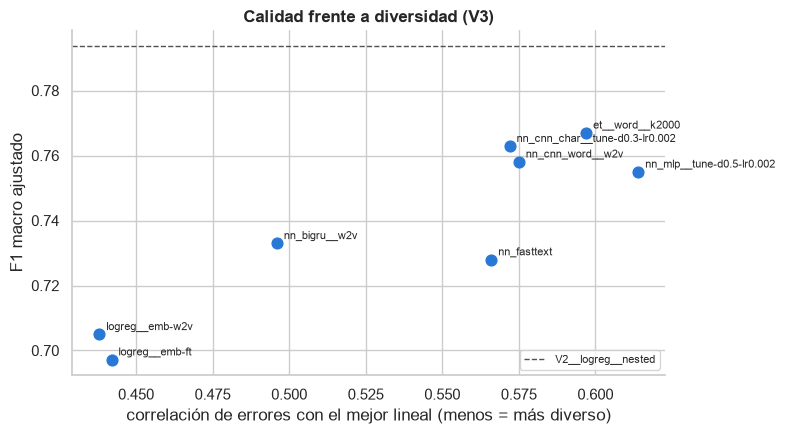

In [11]:
def crossfit_pred(oof):
    pred = np.zeros_like(Y)
    for k in sorted(folds.unique()):
        val = (folds == k).to_numpy()
        pred[val] = md.apply_decision(oof[val], md.best_thresholds(Y[~val], oof[~val]), hierarchy=True)
    return pred


best_per_arch = {}
for i, r in RESULTS.items():
    if r["variant"] == "V3" and "folds2" not in i and r["stage"] not in ("confirmación", "referencia"):
        key = r["classifier"] if r["kind"] == "nn" else f"{r['classifier']}+{i.split('__')[-1]}"
        if key not in best_per_arch or r["cv"]["tuned"]["F1_macro"].mean() > RESULTS[best_per_arch[key]]["cv"]["tuned"]["F1_macro"].mean():
            best_per_arch[key] = i
ref_pred = crossfit_pred(REFS[REF]["oof"])
ref_ok = (ref_pred == Y).all(axis=1)
rows = []
for key, i in list(best_per_arch.items()) + [("ExtraTrees (04)", "V3__et__word__k2000")]:
    pred = crossfit_pred(cv_of(i)["oof"])
    ok = (pred == Y).all(axis=1)
    rows.append({"modelo": i, "F1 macro": round(cv_of(i)["tuned"]["F1_macro"].mean(), 4),
                 "correlación de errores con el lineal": round(np.corrcoef((pred != Y).ravel(), (ref_pred != Y).ravel())[0, 1], 3),
                 "% red acierta y lineal falla": round(100 * np.mean(ok & ~ref_ok), 1),
                 "% lineal acierta y red falla": round(100 * np.mean(ref_ok & ~ok), 1)})
comp = pd.DataFrame(rows).set_index("modelo").sort_values("correlación de errores con el lineal")
display(comp)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(comp["correlación de errores con el lineal"], comp["F1 macro"], s=60, color="#2a78d6")
for mid, row in comp.iterrows():
    ax.annotate(mid.replace("V3__", ""), (row["correlación de errores con el lineal"], row["F1 macro"]),
                textcoords="offset points", xytext=(5, 3), fontsize=8)
ax.axhline(REFS[REF]["tuned"]["F1_macro"].mean(), color="#52514e", ls="--", lw=1, label=f"{REF}")
ax.set(xlabel="correlación de errores con el mejor lineal (menos = más diverso)", ylabel="F1 macro ajustado",
       title="Calidad frente a diversidad (V3)")
ax.legend(fontsize=8)
fig.tight_layout()
savefig(fig, "diversity")
plt.show()

**Interpretación:**
- **Las redes se equivocan en tuits bastante distintos a los del mejor lineal:** la correlación de errores es de **0.50–0.61**, como ExtraTrees (0.60), el modelo más diverso del `04`. Entre los lineales del `04` era de 0.77–0.89.
- **El intercambio es asimétrico:** cada red acierta las tres etiquetas en el **6.0–7.2%** de los tuits que el lineal falla, pero falla en el 8.2–15.1% de los que el lineal acierta.
- **Los mejores equilibrios** son los de:
  - **CNN de caracteres** (acierta en el 7.2% de los fallos del lineal y falla en el 10.9% de sus aciertos);
  - **CNN de palabras con Word2Vec** (6.7% y 9.4%);
  - **MLP** (6.7% y 8.2%, aunque con la correlación más alta, 0.61).
- **Los embeddings promediados** (0.44) y la **BiGRU** (0.50) son los más diversos, pero fallan demasiado: en el 15–20% de los tuits que el lineal acierta.

## 9. Análisis de errores con la atención de la BiGRU

Usamos las redes BiGRU **de cada fold** (las mismas que dieron las predicciones OOF, así que nunca vieron estos tuits) y mostramos, para 8 tuits del fold de validación, las 4 palabras con mayor peso de atención (media de las 3 semillas):
- 4 en los que la BiGRU se equivoca y el lineal acierta;
- 4 en los que la BiGRU acierta y el lineal se equivoca.

Los ejemplos se eligen al azar con `SEED`.

In [12]:
gru_id = md.model_name("V3", "nn_bigru", "tfidf")
gru = RESULTS[gru_id]
gru_pred = crossfit_pred(gru["cv"]["oof"])
gru_ok = (gru_pred == Y).all(axis=1)
rng = np.random.default_rng(SEED)
picks = list(rng.choice(np.where(~gru_ok & ref_ok)[0], 4, replace=False)) + list(rng.choice(np.where(gru_ok & ~ref_ok)[0], 4, replace=False))
rows = []
for idx in picks:
    k = folds.iloc[idx]
    model = gru["cv"]["models"][sorted(folds.unique()).index(k)]
    att = model.attention(texts.iloc[[idx]])[0]
    top = sorted(att, key=lambda t: -t[1])[:4]
    rows.append({"caso": "BiGRU falla, lineal acierta" if not gru_ok[idx] else "BiGRU acierta, lineal falla",
                 "texto": texts.iloc[idx][:110], "real": "".join(map(str, Y[idx])),
                 "BiGRU": "".join(map(str, gru_pred[idx])), "lineal": "".join(map(str, ref_pred[idx])),
                 "palabras con más atención": ", ".join(f"{w} ({p:.2f})" for w, p in top)})
display(pd.DataFrame(rows))

,caso,texto,real,BiGRU,lineal,palabras con más atención
0,"BiGRU falla, lineal acierta",@nick17buero Opaa jajaja comemela entonces ajajaj,000,101,000,"jaja (0.31), entonces (0.24), comemela (0.21), jaja (0.14)"
1,"BiGRU falla, lineal acierta",Tu sabes porque a las mujeres hay que enterralas en un atauld triangular? Po...,100,000,100,"hay (0.22), a (0.13), sabes (0.11), tu (0.08)"
2,"BiGRU falla, lineal acierta",la pedroche que buena est y que feminista es pero la chica de tu barrio que ...,111,000,111,"una (0.20), es (0.14), la (0.09), que (0.07)"
3,"BiGRU falla, lineal acierta",Xdios odio a estos arabes q se extingan,101,100,101,"a (0.23), se (0.21), q (0.19), arabes (0.15)"
4,"BiGRU acierta, lineal falla",Trump advierte a indocumentados consecuencias entrar a EU con o sin nios htt...,000,000,100,"con (0.20), ninos (0.14), trump (0.12), indocumentados (0.09)"
5,"BiGRU acierta, lineal falla",Putos inmigrantes !! https://t.co/M7H7lQYaPv,101,101,001,"putos (0.48), inmigrantes (0.29), <URL> (0.23)"
6,"BiGRU acierta, lineal falla",Yo si fuese @pablocasado_ incluira en mi programa la construccin de un muro ...,100,100,000,"subsaharianos (0.27), los (0.14), yo (0.08), si (0.05)"
7,"BiGRU acierta, lineal falla",@DrodriguezVen @mauriciomacri Callate perra mona que aqu uds no respetan nad...,111,111,110,"perra (0.55), callate (0.39), pasa (0.02), el (0.01)"


**Interpretación:**
- **Cuando la BiGRU acierta y el lineal no, la atención se concentra en las palabras clave:**
  - *putos* (0.48) e *inmigrantes* (0.29) en *"Putos inmigrantes !!"* (101);
  - *perra* (0.55) y *callate* (0.39) en un insulto directo (111);
  - *subsaharianos* (0.27) en un tuit de odio sin insultos (100).
- **Cuando falla, la atención se dispersa en palabras vacías** (*hay*, *a*, *una*, *es*, *que*):
  - el chiste misógino sin insultos (*"a las mujeres hay que enterrarlas en un ataúd triangular"*, 100) no lo detecta;
  - en *"odio a estos arabes q se extingan"* acierta HS pero no AG;
  - a un *"comemela ... jaja"* le da odio y agresividad que no tiene.

Con 1.2k ejemplos, la BiGRU aprende a fijarse en los insultos explícitos, pero no en el odio expresado con estructuras más sutiles.

## 10. Guardado (contrato para el notebook 07)

- **Registro y predicciones:** todos los modelos de este notebook evaluados con los folds principales se añaden a `models/registry.csv` (familia `neuronal`, con arquitectura, hiperparámetros, semillas, épocas del modelo final y tiempo de entrenamiento) y a los parquet de predicciones OOF y de test. Las probabilidades de las redes son la **media de las 3 semillas**. Las evaluaciones en `folds_seed2` son solo de confirmación y no se registran.
- **Archivos** (en `models/05_redes_neuronales/`): se guardan con `.pt` (state_dict de cada semilla, configuración, vocabularios, TF-IDF y versiones; sin pickle de clases) + `.json`:
  - los modelos de las 6 variantes de los finalistas;
  - la mejor red de cada arquitectura en V3.

  La mejor regresión logística sobre embeddings se guarda como `.joblib`.
- **Prueba de carga:** cada modelo guardado, cargado con `modeling.load_model()`, debe dar las mismas probabilidades de test que en memoria (tolerancia 1e-5).

In [13]:
to_save = set(var_ids.values()) | set(best_per_arch.values())
rows, oof_frames, test_frames, checks = [], [], [], []
for mid, r in RESULTS.items():
    if "model" not in r or r["stage"] == "referencia":
        continue
    model, cv = r["model"], r["cv"]
    saved = mid in to_save
    meta = {"notebook": "05", "stage": r["stage"],
            "cv": {s: {m: {"mean": float(cv[s][m].mean()), "std": float(cv[s][m].std())} for m in cv[s].columns}
                   for s in ("at_05", "tuned")},
            "cv_folds_file": "data/processed/folds.csv", "n_train": len(train),
            "thresholds_source": "F1 máximo sobre todas las OOF de la CV"}
    if "train" in cv:
        meta["cv_train"] = {m: {"mean": float(cv["train"][m].mean()), "std": float(cv["train"][m].std())} for m in cv["train"].columns}
    if r["kind"] == "nn":
        meta.update({"best_epochs_cv": cv["best_epochs"], "seed_f1_macro": [float(s["F1_macro"].mean()) for s in cv["tuned_per_seed"]],
                     "cv_inner_val": {m: {"mean": float(cv["inner_val"][m].mean())} for m in cv["inner_val"].columns}})
        extra = {"architecture": md.CLASSIFIER_NAMES[r["classifier"]], "seeds": model.n_seeds, "epochs": model.fixed_epochs,
                 "train_seconds": round(model.train_seconds_, 1)}
        if saved:
            path = nn_.save_neural_model(model, mid, meta)
    else:
        extra = None
        if saved:
            path = md.save_model(model, mid, meta)
    if saved:
        reloaded = md.load_model(path)
        checks.append({"model_id": mid, "archivo": path.name,
                       "máx. diferencia de probabilidad": float(np.abs(reloaded.predict_proba(test["text"]) - r["test_proba"]).max())})
    rows.append(md.registry_row(mid, model, cv, notebook="05", saved=saved, size_mb=r["size_mb"], extra=extra))
    oof_frames.append(md.prediction_frame(mid, train["id"], cv["oof"], fold=folds, calibrated=False))
    test_frames.append(md.prediction_frame(mid, test["id"], r["test_proba"], pred=r["test_pred"], calibrated=False))

registry = md.update_registry(rows)
md.update_predictions(oof_frames, md.OOF_PATH)
md.update_predictions(test_frames, md.TEST_PRED_PATH)
checks = pd.DataFrame(checks).set_index("model_id")
display(checks)
assert (checks["máx. diferencia de probabilidad"] <= 1e-5).all(), "algún modelo no reproduce sus probabilidades al cargarlo"
print(f"Registro: {len(registry)} modelos ({(registry['notebook'] == '05').sum()} del 05) | guardados en este notebook: {len(checks)}")
display(registry[registry["notebook"] == "05"].head(12)[["model_id", "family", "architecture", "params", "F1_macro",
                                                         "F1_macro_std", "seeds", "epochs", "train_seconds", "size_mb", "saved"]])

,archivo,máx. diferencia de probabilidad
model_id,,
V3__nn_fasttext,V3__nn_fasttext.pt,0.0
V3__logreg__emb-w2v,V3__logreg__emb-w2v.joblib,0.0
V3__logreg__emb-ft,V3__logreg__emb-ft.joblib,0.0
V3__nn_cnn_word__w2v,V3__nn_cnn_word__w2v.pt,0.0
V3__nn_bigru__w2v,V3__nn_bigru__w2v.pt,0.0
V3__nn_cnn_char__tune-d0.3-lr0.002,V3__nn_cnn_char__tune-d0.3-lr0.002.pt,0.0
V3__nn_mlp__tune-d0.5-lr0.002,V3__nn_mlp__tune-d0.5-lr0.002.pt,0.0
V0__nn_cnn_char__tune-d0.3-lr0.002,V0__nn_cnn_char__tune-d0.3-lr0.002.pt,0.0
V1__nn_cnn_char__tune-d0.3-lr0.002,V1__nn_cnn_char__tune-d0.3-lr0.002.pt,0.0


Registro: 166 modelos (40 del 05) | guardados en este notebook: 17


,model_id,family,architecture,params,F1_macro,F1_macro_std,seeds,epochs,train_seconds,size_mb,saved
43,V1__nn_cnn_char__tune-d0.3-lr0.002,neuronal,CNN de caracteres,"{""batch_size"": 64, ""dropout"": 0.3, ""emb_dim"": 32, ""filters"": 64, ""head"": ""sh...",0.7654,0.0243,3.0,13.0,115.1,0.42,True
44,V1__nn_cnn_word__w2v,neuronal,CNN de palabras,"{""batch_size"": 64, ""dropout"": 0.5, ""emb_dim"": 100, ""filters"": 64, ""head"": ""s...",0.7644,0.0114,3.0,11.0,37.6,3.13,True
45,V2__nn_cnn_word__w2v,neuronal,CNN de palabras,"{""batch_size"": 64, ""dropout"": 0.5, ""emb_dim"": 100, ""filters"": 64, ""head"": ""s...",0.7644,0.0098,3.0,11.0,37.2,3.12,True
47,V3__nn_cnn_char__tune-d0.3-lr0.002,neuronal,CNN de caracteres,"{""batch_size"": 64, ""dropout"": 0.3, ""emb_dim"": 32, ""filters"": 64, ""head"": ""sh...",0.7629,0.0155,3.0,12.0,106.3,0.43,True
48,V4__nn_cnn_char__tune-d0.3-lr0.002,neuronal,CNN de caracteres,"{""batch_size"": 64, ""dropout"": 0.3, ""emb_dim"": 32, ""filters"": 64, ""head"": ""sh...",0.7629,0.0155,3.0,12.0,106.7,0.43,True
51,V1__nn_cnn_char,neuronal,CNN de caracteres,"{""batch_size"": 64, ""dropout"": 0.5, ""emb_dim"": 32, ""filters"": 64, ""head"": ""sh...",0.7607,0.0156,3.0,25.0,229.7,0.42,False
53,V1__nn_cnn_word,neuronal,CNN de palabras,"{""batch_size"": 64, ""dropout"": 0.5, ""emb_dim"": 100, ""filters"": 64, ""head"": ""s...",0.7601,0.0168,3.0,10.0,30.8,3.13,False
57,V3__nn_cnn_word__w2v,neuronal,CNN de palabras,"{""batch_size"": 64, ""dropout"": 0.5, ""emb_dim"": 100, ""filters"": 64, ""head"": ""s...",0.7581,0.0072,3.0,11.0,37.2,3.09,True
58,V3__nn_cnn_char__tune-d0.5-lr0.002,neuronal,CNN de caracteres,"{""batch_size"": 64, ""dropout"": 0.5, ""emb_dim"": 32, ""filters"": 64, ""head"": ""sh...",0.7579,0.0254,3.0,15.0,133.6,0.43,False
61,V3__nn_cnn_char__indep,neuronal,CNN de caracteres,"{""batch_size"": 64, ""dropout"": 0.5, ""emb_dim"": 32, ""filters"": 64, ""head"": ""in...",0.7569,0.0124,3.0,20.0,536.3,1.26,False


## 11. Conclusiones

### F1 de las redes frente al mejor lineal (F1 macro ajustado, 5 folds)

| Modelo | F1 macro | Δ frente a `V2__logreg__nested` (0.794) | En `folds_seed2` |
|---|---|---|---|
| **CNN de caracteres** (V1, dropout 0.3, lr 0.002) | **0.765 ± 0.024** | −0.028 ± 0.027 (peor) | — |
| **CNN de palabras + Word2Vec propio** (V1 / V2) | **0.764 ± 0.011** | −0.029 (peor) | V3: **0.771 ± 0.032, empate** (−0.015 ± 0.019) |
| CNN de caracteres (V3, misma configuración) | 0.763 ± 0.016 | −0.031 (peor) | 0.760 (peor) |
| MLP sobre TF-IDF (V3, dropout 0.5, lr 0.002) | 0.755 ± 0.011 | −0.039 (peor) | — |
| BiGRU con atención (V1) | 0.733 ± 0.016 | −0.061 (peor) | — |
| Estilo fastText (V1) | 0.732 ± 0.017 | −0.062 (peor) | — |
| Word2Vec propio promediado + regresión logística (V3) | 0.705 ± 0.028 | −0.089 (peor) | — |
| *Referencia: SVM lineal V3* | *0.782 ± 0.016* | *−0.012* | *0.785, empate* |

**Qué decisiones de diseño importaron:**
- **Sí:**
  - **promediar 3 semillas** (+0.006 de mediana, hasta +0.027);
  - **la limpieza del texto** (V1 − V0: +0.022 a +0.047);
  - **la restauración en la CNN de caracteres** (+0.011, consistente).
- **Algo, pero dentro del ruido:** **inicializar con Word2Vec o FastText propios** en la CNN de palabras (+0.011/+0.013, 4 de 5 folds). Además la regulariza y reduce la variación entre semillas.
- **No:**
  - **3 redes independientes** frente a cabeza compartida (empate, y 3 veces más caro);
  - **`pos_weight`** (empeora en los 5 folds);
  - **los lemas** (−0.020 en la CNN de palabras);
  - el ajuste fino de dropout y tasa de aprendizaje (≤ 0.007, menos que el ruido de la semilla).

**Sobreajuste:** todas las redes tienen brecha train − validación de 0.09–0.21, y los lineales de ≈0.21. El problema de las redes no es que memoricen más, sino que con 1.4k ejemplos no aprenden representaciones mejores que el conteo de n-gramas.

**Diversidad:** sí aportan. Su correlación de errores con el mejor lineal es de 0.50–0.61, frente a 0.77–0.89 entre lineales, y aciertan el 6–7% de los tuits que el lineal falla.

**Recomendación para el ensamble del `07`:**
- `V1__nn_cnn_char__tune-d0.3-lr0.002` (o su versión V3) y `V1__nn_cnn_word__w2v` (o la de V2): las mejores redes y las que mejor equilibran lo que aportan frente a lo que fallan;
- opcionalmente `V3__nn_mlp__tune-d0.5-lr0.002`;
- no recomiendo la BiGRU, fastText ni los embeddings promediados: son diversos, pero fallan demasiado.

Sus probabilidades (media de 3 semillas, sin calibrar) ya están en los parquet compartidos.

**Límites y pendientes:**
- **Reproducibilidad:** solo hay una ejecución completa. El entrenamiento en CPU es determinista (semillas fijas y `torch.use_deterministic_algorithms`), y la recarga de los 17 modelos guardados da diferencia 0.0. La comprobación con una segunda ejecución completa queda pendiente.
- **Tiempo:** el notebook tardó ≈3 h 10 min. La CNN de caracteres cuesta 8–12 min por CV completa (dentro del tope), pero con 3 redes independientes tardó 31 min (fuera del tope; se hizo una sola vez).
- **Elección optimista:** las configuraciones se eligen en los mismos folds en que se miden. La confirmación en `folds_seed2` muestra que las redes se sostienen (cambios de −0.003 a +0.013), pero también que la ventaja de la regresión logística del `04` se reduce (0.794 → 0.786).
- **Datos adicionales que podrían ayudar, propuestos y no usados** (hay que consultarlo antes con el profesor por licencias, P4, y transductividad):
  - entrenar Word2Vec o FastText también con los textos del test, sin etiquetas;
  - un corpus externo de tuits en español con licencia abierta y citada.

  Con solo ≈24 mil palabras por fold, los embeddings propios son débiles, y es ahí donde más margen hay.